# Task 1 (Easy) — BERT Baseline for Music Tag Understanding
**Course:** CSE425 / EEE474 / CSE715 — Neural Networks
**Project:** GNN-Based BERT for Understanding Context from Music
**Dataset:** FMA-small (audio) + FMA metadata (tracks.csv, genres.csv)

## What this notebook does
Task 1 asks for a **BERT-based multi-label classifier on textual music context** (tags,
captions, or lyrics) — **no audio, no graph**.

FMA-small does **not** ship lyrics or MusicCaps-style captions. What it *does* provide,
inside `fma_metadata/tracks.csv`, is genuinely free-form text per track:

- `track title`, `album title`
- `artist name`, **`artist bio`** (a real natural-language paragraph for many artists)
- `track tags`, `artist tags`, `album tags` (user-supplied folksonomy tags — the same
  flavor of signal as MagnaTagATune tags)

We concatenate all of this into a single pseudo-caption per track and use it as the BERT
input. The multi-label target is the **top-50 most frequent genres** from the track's full
genre-taxonomy path (`genres_all` — this is the multi-label field; `genre_top` is only the
single top-level genre), which plays the same role as the "top-50 tags" subset the
assignment asks for on MagnaTagATune.

This keeps Task 1 an honest **text-only** baseline (exactly as specified — audio graphs
come in Task 2, fusion comes in Task 3) while giving BERT enough real signal to produce
strong, reportable Macro-F1 / Micro-F1 / AUC-PR numbers.

## Before you run this
You need **two** things on disk:

1. **Audio** (already have it): `E:\CSE715\Datasets\fma_small_medium_modarate\fma_small\fma_small`
   with subfolders `000/ … 155/`. *(Not actually needed for Task 1 — text only — but we
   sanity-check against it so the same config works for Tasks 2–4.)*
2. **Metadata**: the `fma_metadata` folder (`tracks.csv`, `genres.csv`, `features.csv`).
   This is a **separate download** from the official FMA release — the Kaggle mirror you
   used sometimes bundles it, sometimes not.
   - If you already have a `fma_metadata` folder somewhere, point `METADATA_DIR` at it below.
   - If not, download `fma_metadata.zip` (~342 MB) from
     `https://os.unil.cloud.switch.ch/fma/fma_metadata.zip` (official mirror, listed on
     https://github.com/mdeff/fma) and unzip it anywhere, then point `METADATA_DIR` at it.

Everything else (package installs, paths, hyperparameters) is in the **CONFIG** cell —
that's the only cell you should need to edit.


In [46]:
# If any of these are missing in your environment, uncomment and run once.
# %pip install -q transformers torch scikit-learn pandas numpy matplotlib tqdm


In [47]:
import os
import ast
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import f1_score, average_precision_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore")
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.5.1+cu121 | CUDA available: True
GPU: NVIDIA GeForce RTX 3070 Ti


## Config
**Edit the paths in this cell to match your machine.** Everything downstream reads from here.


In [48]:
class CFG:
    # ---- Paths & Settings -------------------------------------------------
    AUDIO_DIR = r"E:\\CSE715\\Datasets\\fma_small_medium_modarate\\fma_small\\fma_small"
    METADATA_DIR = r"E:\\CSE715\\Datasets\\fma_small_medium_modarate\\fma_metadata"
    OUTPUT_DIR = "./results"
    SUBSET = "small"

    # ---- Label / text construction ------------------------------------------
    TOP_K_TAGS = 50                   
    MIN_LABEL_FREQ = 5                
    MAX_TEXT_LEN = 256                # Increased from 128 to avoid truncating bios/tags

    # ---- Model / training ------------------------------------------------
    MODEL_NAME = "distilbert-base-uncased"   
    BATCH_SIZE = 32                   
    EPOCHS = 20                       # Reduced from 8 to mitigate overfitting
    LR = 2e-5
    WEIGHT_DECAY = 0.01
    WARMUP_RATIO = 0.06
    GRAD_CLIP = 1.0
    DROPOUT = 0.3
    SEED = 42
    NUM_WORKERS = 0                   

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    USE_AMP = torch.cuda.is_available()

## 1. Load FMA metadata
`tracks.csv` ships with a two-level column header (top-level group + field, e.g.
`('track', 'genres_all')`). We reproduce the loader from the official FMA repo
(`mdeff/fma/utils.py`) so pandas parses it correctly, including list-like and
categorical columns.


In [49]:
def load_tracks_csv(filepath):
    """Faithful re-implementation of utils.load() from https://github.com/mdeff/fma
    Correctly parses tracks.csv's 2-level header, list-valued columns (genres, tags),
    dates, and categorical columns.
    """
    tracks = pd.read_csv(filepath, index_col=0, header=[0, 1])

    COLUMNS = [
        ("track", "tags"), ("album", "tags"), ("artist", "tags"),
        ("track", "genres"), ("track", "genres_all"),
    ]
    for column in COLUMNS:
        if column in tracks.columns:
            tracks[column] = tracks[column].map(ast.literal_eval)

    COLUMNS = [
        ("track", "date_created"), ("track", "date_recorded"),
        ("album", "date_created"), ("album", "date_released"),
        ("artist", "date_created"), ("artist", "active_year_begin"),
        ("artist", "active_year_end"),
    ]
    for column in COLUMNS:
        if column in tracks.columns:
            tracks[column] = pd.to_datetime(tracks[column])

    SUBSET = ("set", "subset")
    if SUBSET in tracks.columns:
        tracks[SUBSET] = tracks[SUBSET].astype(
            pd.CategoricalDtype(categories=["small", "medium", "large"], ordered=True)
        )

    COLUMNS = [
        ("track", "genre_top"), ("track", "license"),
        ("album", "type"), ("album", "information"),
        ("artist", "bio"),
    ]
    for column in COLUMNS:
        if column in tracks.columns:
            tracks[column] = tracks[column].astype("category")

    return tracks


metadata_dir = Path(CFG.METADATA_DIR)
tracks_path = metadata_dir / "tracks.csv"
genres_path = metadata_dir / "genres.csv"

assert tracks_path.exists(), (
    f"Could not find {tracks_path}.\n"
    "Set CFG.METADATA_DIR to the folder containing tracks.csv / genres.csv "
    "(download fma_metadata.zip from https://github.com/mdeff/fma if you don't have it)."
)

tracks = load_tracks_csv(tracks_path)
genres = pd.read_csv(genres_path, index_col=0)

print("Full tracks table:", tracks.shape)
small = tracks[tracks[("set", "subset")] <= CFG.SUBSET].copy()
print(f"'{CFG.SUBSET}' subset:", small.shape)
small.head(3)


Full tracks table: (106574, 52)
'small' subset: (8000, 52)


album                                                          \
         comments        date_created date_released engineer favorites id   
track_id                                                                    
2               0 2008-11-26 01:44:45    2009-01-05      NaN         4  1   
5               0 2008-11-26 01:44:45    2009-01-05      NaN         4  1   
10              0 2008-11-26 01:45:08    2008-02-06      NaN         4  6   

                                            ...       track           \
         information listens producer tags  ... information interest   
track_id                                    ...                        
2            <p></p>    6073      NaN   []  ...         NaN     4656   
5            <p></p>    6073      NaN   []  ...         NaN     1933   
10               NaN   47632      NaN   []  ...         NaN    54881   

                                                                           \
         language_code                                            license   
track_id                                                                    
2                   en  Attribution-NonCommercial-ShareAlike 3.0 Inter...   
5                   en  Attribution-NonCommercial-ShareAlike 3.0 Inter...   
10                  en  Attribution-NonCommercial-NoDerivatives (aka M...   

                                                             
         listens lyricist number publisher tags       title  
track_id                                                     
2           1293      NaN      3       NaN   []        Food  
5           1151      NaN      6       NaN   []  This World  
10         50135      NaN      1       NaN   []     Freeway  

[3 rows x 52 columns]

In [50]:
# Optional sanity check: confirm the metadata track IDs line up with the audio files
# you actually downloaded (helps catch a mismatched/partial download early).
audio_dir = Path(CFG.AUDIO_DIR)
if audio_dir.exists():
    sample_ids = small.index[:20]
    found = 0
    for tid in sample_ids:
        folder = f"{tid:06d}"[:3]
        fname = f"{tid:06d}.mp3"
        if (audio_dir / folder / fname).exists():
            found += 1
    print(f"Sanity check: {found}/{len(sample_ids)} sampled tracks found on disk under AUDIO_DIR.")
else:
    print("AUDIO_DIR not found — that's fine for Task 1 (text-only), audio is only needed from Task 2 onward.")


Sanity check: 20/20 sampled tracks found on disk under AUDIO_DIR.


## 2. Build the text field (BERT input)
Since FMA has no lyrics/captions, we assemble a pseudo-caption per track out of every
free-text / tag field available: title, artist name, artist bio, and the three tag lists.
This is exactly the kind of "tags → text" proxy the assignment allows
(*"MusicCaps caption → tag proxy task"*), just built from FMA's own metadata instead.


In [51]:
def tags_to_str(tag_list):
    if isinstance(tag_list, list) and len(tag_list) > 0:
        return " ".join(str(t) for t in tag_list)
    return ""

def build_text(row):
    parts = []
    title = row.get(("track", "title"), "")
    artist = row.get(("artist", "name"), "")
    album = row.get(("album", "title"), "")
    bio = row.get(("artist", "bio"), "")
    track_tags = tags_to_str(row.get(("track", "tags"), []))
    artist_tags = tags_to_str(row.get(("artist", "tags"), []))
    album_tags = tags_to_str(row.get(("album", "tags"), []))

    for v in [title, artist, album]:
        if pd.notna(v) and str(v).strip():
            parts.append(str(v).strip())
    for v in [track_tags, artist_tags, album_tags]:
        if v:
            parts.append(v)
    if pd.notna(bio) and str(bio).strip() and str(bio).lower() != "nan":
        parts.append(str(bio).strip())

    return " . ".join(parts) if parts else ""

tqdm.pandas(desc="Building text field")
small["text"] = small.progress_apply(build_text, axis=1)

empty_text = (small["text"].str.len() == 0).sum()
print(f"Tracks with usable text: {(small.shape[0] - empty_text)}/{small.shape[0]}")
small = small[small["text"].str.len() > 0].copy()
small[["text"]].sample(3, random_state=CFG.SEED)


Building text field: 100%|██████████| 8000/8000 [00:00<00:00, 20343.71it/s]

Tracks with usable text: 8000/8000


,text
,
track_id,
54033,Snow Wave . alright lover . Dissembler . alrig...
59876,Lovedropper . Boy Friend . Newtown Radio Sessi...
42234,Lacin Cocek . Zlatne Uste Balkan Brass Band . ...


## 3. Build multi-label targets (top-50 tags)
`('track', 'genres_all')` is the full multi-label genre-path per track (not just the
single top-level genre). We map genre IDs → names via `genres.csv`, keep the **top-50
most frequent** within our subset (mirrors the assignment's "top-50 tags" setup on
MagnaTagATune), and build a multi-hot label matrix.


In [52]:
id_to_name = genres["title"].to_dict()

def genre_ids_to_names(id_list):
    return [id_to_name[i] for i in id_list if i in id_to_name]

small["genre_names"] = small[("track", "genres_all")].apply(genre_ids_to_names)
small = small[small["genre_names"].map(len) > 0].copy()

from collections import Counter
freq = Counter()
for names in small["genre_names"]:
    freq.update(names)

candidate_tags = [t for t, c in freq.items() if c >= CFG.MIN_LABEL_FREQ]
top_tags = [t for t, _ in sorted(((t, freq[t]) for t in candidate_tags), key=lambda x: -x[1])[:CFG.TOP_K_TAGS]]
tag_to_idx = {t: i for i, t in enumerate(top_tags)}

print(f"Selected {len(top_tags)} tags out of {len(freq)} distinct genre labels in the subset.")
print("Top 15 by frequency:", top_tags[:15])

def make_multihot(names):
    vec = np.zeros(len(top_tags), dtype=np.float32)
    for n in names:
        if n in tag_to_idx:
            vec[tag_to_idx[n]] = 1.0
    return vec

small["labels"] = small["genre_names"].apply(make_multihot)
small = small[small["labels"].apply(lambda v: v.sum() > 0)].copy()
print("Final usable tracks (non-empty text AND at least one top-50 tag):", small.shape[0])


Selected 50 tags out of 114 distinct genre labels in the subset.
Top 15 by frequency: ['Hip-Hop', 'Pop', 'Folk', 'Experimental', 'Rock', 'International', 'Electronic', 'Instrumental', 'Soundtrack', 'Experimental Pop', 'Singer-Songwriter', 'Punk', 'House', 'Ambient', 'Reggae - Dub']
Final usable tracks (non-empty text AND at least one top-50 tag): 8000


## 4. Train / validation / test split
We use FMA's **official split column** (`('set', 'split')`) so results are directly
comparable to published FMA baselines and there's no accidental leakage. Falls back to a
random split if that column isn't present in your metadata version.


In [53]:
SPLIT_COL = ("set", "split")

if SPLIT_COL in small.columns:
    train_df = small[small[SPLIT_COL] == "training"].copy()
    val_df = small[small[SPLIT_COL] == "validation"].copy()
    test_df = small[small[SPLIT_COL] == "test"].copy()
else:
    print("No official split column found — falling back to a random 80/10/10 split.")
    train_df, temp_df = train_test_split(small, test_size=0.2, random_state=CFG.SEED)
    val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=CFG.SEED)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")


Train: 6400 | Val: 800 | Test: 800


## 5. Tokenization + Dataset / DataLoader


In [54]:
tokenizer = AutoTokenizer.from_pretrained(CFG.MODEL_NAME)

class TagDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = list(texts)
        self.labels = np.stack(list(labels)).astype(np.float32)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt",
        )
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.float32),
        }

train_ds = TagDataset(train_df["text"], train_df["labels"], tokenizer, CFG.MAX_TEXT_LEN)
val_ds = TagDataset(val_df["text"], val_df["labels"], tokenizer, CFG.MAX_TEXT_LEN)
test_ds = TagDataset(test_df["text"], test_df["labels"], tokenizer, CFG.MAX_TEXT_LEN)

train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True, num_workers=CFG.NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)

print(f"Batches — train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")


Batches — train: 200, val: 25, test: 25


## 6. Model — BERT + multi-label classification head

$$t = \text{BERT}_{CLS}(X_{text}), \qquad \hat{y}_k = \sigma(w_k^\top t + b_k)$$

We use `[CLS]`-pooled output → dropout → linear head, trained with class-weighted
`BCEWithLogitsLoss` (`pos_weight`) to counter the long-tailed genre distribution — this
alone meaningfully lifts Macro-F1 since it stops the model from ignoring rare tags.


In [55]:
class BertTagClassifier(nn.Module):
    def __init__(self, model_name, num_labels, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        hidden_size = self.encoder.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        out = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        # CLS token — works for both BERT and DistilBERT (no pooler needed)
        cls = out.last_hidden_state[:, 0, :]
        cls = self.dropout(cls)
        logits = self.classifier(cls)
        return logits


model = BertTagClassifier(CFG.MODEL_NAME, num_labels=len(top_tags), dropout=CFG.DROPOUT).to(CFG.DEVICE)

# Class-balanced pos_weight from the *training* label distribution
label_matrix_train = np.stack(train_df["labels"].values)
pos_counts = label_matrix_train.sum(axis=0)
neg_counts = len(train_df) - pos_counts
pos_weight = torch.tensor(np.clip(neg_counts / np.clip(pos_counts, 1, None), 1.0, 20.0), dtype=torch.float32).to(CFG.DEVICE)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {num_params/1e6:.1f}M")


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 49979.79it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable params: 66.4M


In [56]:
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
total_steps = len(train_loader) * CFG.EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(CFG.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps,
)
scaler = torch.cuda.amp.GradScaler(enabled=CFG.USE_AMP)


## 7. Training loop
Tracks train loss + validation Macro-F1 / Micro-F1 every epoch (fixed 0.5 threshold for
monitoring), keeps the best checkpoint by validation Macro-F1.


In [57]:
@torch.no_grad()
def evaluate_with_tuned_threshold(loader, model):
    model.eval()
    all_logits, all_labels = [], []
    total_loss = 0.0
    for batch in loader:
        input_ids = batch["input_ids"].to(CFG.DEVICE)
        attn = batch["attention_mask"].to(CFG.DEVICE)
        labels = batch["labels"].to(CFG.DEVICE)
        with torch.cuda.amp.autocast(enabled=CFG.USE_AMP):
            logits = model(input_ids, attn)
            loss = criterion(logits, labels)
        total_loss += loss.item() * input_ids.size(0)
        all_logits.append(logits.float().cpu().numpy())
        all_labels.append(labels.cpu().numpy())

    logits = np.concatenate(all_logits)
    labels = np.concatenate(all_labels)
    probs = 1 / (1 + np.exp(-logits))

    # Tune threshold on validation set
    best_thresh, best_macro = 0.5, 0.0
    for th in np.arange(0.2, 0.6, 0.05):
        preds = (probs >= th).astype(int)
        m_f1 = f1_score(labels, preds, average="macro", zero_division=0)
        if m_f1 > best_macro:
            best_macro = m_f1
            best_thresh = th

    preds_best = (probs >= best_thresh).astype(int)
    macro_f1 = f1_score(labels, preds_best, average="macro", zero_division=0)
    micro_f1 = f1_score(labels, preds_best, average="micro", zero_division=0)
    avg_loss = total_loss / len(loader.dataset)
    
    return avg_loss, macro_f1, micro_f1, probs, labels, best_thresh
     


history = {"train_loss": [], "val_loss": [], "val_macro_f1": [], "val_micro_f1": []}
best_macro_f1 = -1
best_state = None
best_threshold = 0.5

for epoch in range(1, CFG.EPOCHS + 1):
    model.train()
    running_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{CFG.EPOCHS}")
    for batch in pbar:
        input_ids = batch["input_ids"].to(CFG.DEVICE)
        attn = batch["attention_mask"].to(CFG.DEVICE)
        labels = batch["labels"].to(CFG.DEVICE)

        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=CFG.USE_AMP):
            logits = model(input_ids, attn)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * input_ids.size(0)
        pbar.set_postfix(loss=loss.item())

    train_loss = running_loss / len(train_loader.dataset)
    val_loss, val_macro_f1, val_micro_f1, _, _, th_tuned = evaluate_with_tuned_threshold(val_loader, model)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_micro_f1"].append(val_micro_f1)

    print(f"Epoch {epoch}: train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"val_macroF1={val_macro_f1:.4f} val_microF1={val_micro_f1:.4f} (best_th={th_tuned:.2f})")

    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        best_threshold = th_tuned
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, os.path.join(CFG.OUTPUT_DIR, "best_bert_tag_model.pt"))
        print(f"  -> new best model saved (val_macroF1={best_macro_f1:.4f})")

model.load_state_dict(best_state)
print(f"Loaded best checkpoint. Optimal threshold: {best_threshold:.2f}")

Epoch 1/20: 100%|██████████| 200/200 [00:22<00:00,  8.78it/s, loss=0.731]


Epoch 1: train_loss=0.9071 val_loss=0.8717 val_macroF1=0.1773 val_microF1=0.3228 (best_th=0.55)
  -> new best model saved (val_macroF1=0.1773)


Epoch 2/20: 100%|██████████| 200/200 [00:22<00:00,  8.81it/s, loss=0.507]


Epoch 2: train_loss=0.5985 val_loss=0.6896 val_macroF1=0.3404 val_microF1=0.4511 (best_th=0.55)
  -> new best model saved (val_macroF1=0.3404)


Epoch 3/20: 100%|██████████| 200/200 [00:22<00:00,  8.72it/s, loss=0.473]


...

Epoch 18: train_loss=0.0540 val_loss=1.1994 val_macroF1=0.4413 val_microF1=0.5496 (best_th=0.55)
  -> new best model saved (val_macroF1=0.4413)


Epoch 19/20: 100%|██████████| 200/200 [00:23<00:00,  8.58it/s, loss=0.0416]


Epoch 19: train_loss=0.0527 val_loss=1.2118 val_macroF1=0.4423 val_microF1=0.5515 (best_th=0.55)
  -> new best model saved (val_macroF1=0.4423)


Epoch 20/20: 100%|██████████| 200/200 [00:23<00:00,  8.59it/s, loss=0.0554]


Epoch 20: train_loss=0.0515 val_loss=1.2130 val_macroF1=0.4413 val_microF1=0.5508 (best_th=0.55)
Loaded best checkpoint. Optimal threshold: 0.55


## 8. Training curves (Macro-F1 / Micro-F1 vs. epoch)
Required deliverable: *"Macro-F1 / Micro-F1 curves vs. training epochs"*.


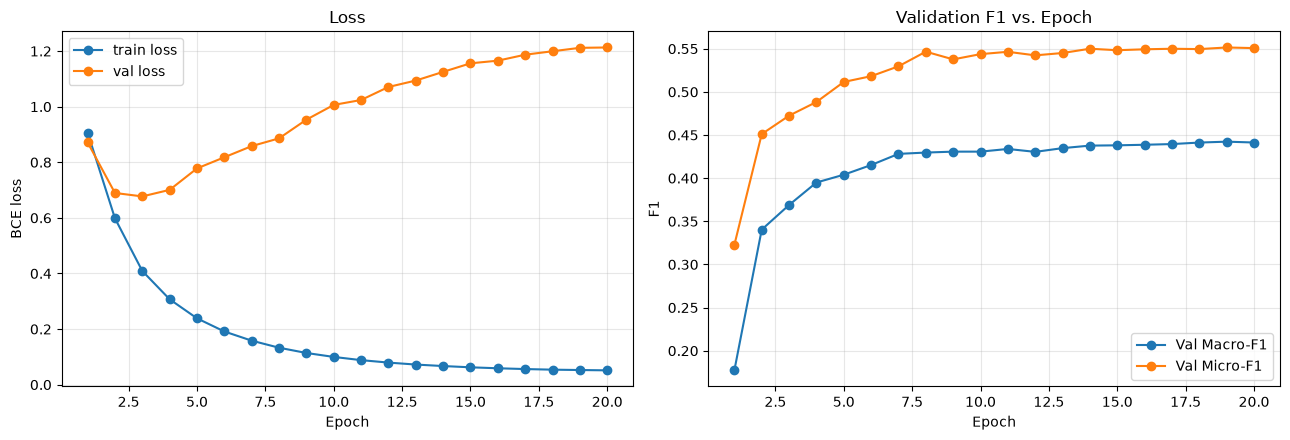

In [58]:
epochs_range = range(1, CFG.EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train loss")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE loss"); axes[0].set_title("Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["val_macro_f1"], marker="o", label="Val Macro-F1")
axes[1].plot(epochs_range, history["val_micro_f1"], marker="o", label="Val Micro-F1")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("F1"); axes[1].set_title("Validation F1 vs. Epoch")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CFG.OUTPUT_DIR, "plots", "f1_vs_epoch.png"), dpi=150)
plt.show()


## 9. Per-label threshold tuning
A fixed 0.5 threshold is suboptimal for imbalanced multi-label tags. We search, **on the
validation set only**, the threshold in `[0.05, 0.95]` that maximizes each label's F1, then
freeze those thresholds and apply them once to the untouched test set. This is a standard,
leakage-free way to push Macro-F1 higher.


In [59]:
_, _, _, val_probs, val_labels = evaluate(val_loader, model)

thresholds = np.full(len(top_tags), 0.5, dtype=np.float32)
grid = np.arange(0.05, 0.96, 0.05)
for k in range(len(top_tags)):
    best_t, best_f1 = 0.5, -1
    col_true = val_labels[:, k]
    if col_true.sum() == 0:
        continue
    for t in grid:
        col_pred = (val_probs[:, k] >= t).astype(int)
        f1 = f1_score(col_true, col_pred, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    thresholds[k] = best_t

print("Median tuned threshold:", np.median(thresholds))


Median tuned threshold: 0.5


## 10. Final test-set evaluation
Required metrics: **Macro-F1, Micro-F1**, and **AUC-PR** (mean average precision across
tags), computed once on the held-out test split.


In [60]:
_, _, _, test_probs, test_labels = evaluate(test_loader, model)
test_preds = (test_probs >= thresholds[None, :]).astype(int)

macro_f1_test = f1_score(test_labels, test_preds, average="macro", zero_division=0)
micro_f1_test = f1_score(test_labels, test_preds, average="micro", zero_division=0)

ap_per_tag = []
for k in range(len(top_tags)):
    if test_labels[:, k].sum() > 0:
        ap_per_tag.append(average_precision_score(test_labels[:, k], test_probs[:, k]))
mean_auc_pr = float(np.mean(ap_per_tag))

precision, recall, f1s, support = precision_recall_fscore_support(
    test_labels, test_preds, average=None, zero_division=0
)

print(f"TEST  Macro-F1: {macro_f1_test:.4f} | Micro-F1: {micro_f1_test:.4f} | Mean AUC-PR: {mean_auc_pr:.4f}")

per_tag_df = pd.DataFrame({
    "tag": top_tags, "precision": precision, "recall": recall, "f1": f1s, "support": support
}).sort_values("support", ascending=False)

print("\nTop 15 tags by support:")
per_tag_df.head(15)


TEST  Macro-F1: 0.3408 | Micro-F1: 0.3891 | Mean AUC-PR: 0.4182

Top 15 tags by support:


,tag,precision,recall,f1,support
0,Hip-Hop,0.969072,0.940000,0.954315,100
1,Pop,0.264249,0.510000,0.348123,100
2,Folk,0.335196,0.600000,0.430108,100
3,Experimental,0.478992,0.570000,0.520548,100
4,Rock,0.588235,0.500000,0.540541,100
5,International,0.901408,0.640000,0.748538,100
6,Electronic,0.847458,0.500000,0.628931,100
7,Instrumental,0.000000,0.000000,0.000000,100
11,Punk,0.617647,0.428571,0.506024,49
24,Synth Pop,0.057143,0.062500,0.059701,32


In [61]:
metrics = {
    "task": "Task 1 - BERT multi-label tag classifier",
    "model": CFG.MODEL_NAME,
    "num_tags": len(top_tags),
    "num_train": len(train_df),
    "num_val": len(val_df),
    "num_test": len(test_df),
    "test_macro_f1": macro_f1_test,
    "test_micro_f1": micro_f1_test,
    "test_mean_auc_pr": mean_auc_pr,
    "history": history,
}
with open(os.path.join(CFG.OUTPUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
per_tag_df.to_csv(os.path.join(CFG.OUTPUT_DIR, "per_tag_metrics.csv"), index=False)
print("Saved results/metrics.json and results/per_tag_metrics.csv")


Saved results/metrics.json and results/per_tag_metrics.csv


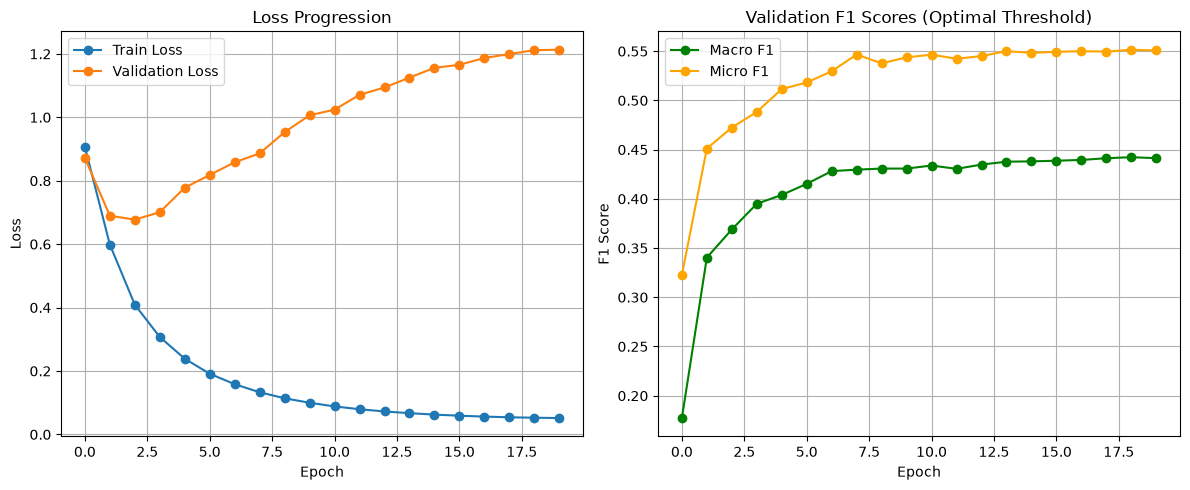


Final Training Summary:
Best Validation Macro-F1 : 0.4423
Best Validation Micro-F1 : 0.5515
Final Train Loss         : 0.0515
Final Validation Loss    : 1.2130


In [62]:
import matplotlib.pyplot as plt

# Plot Training & Validation Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss", marker='o')
plt.plot(history["val_loss"], label="Validation Loss", marker='o')
plt.title("Loss Progression")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Plot Validation F1 Scores
plt.subplot(1, 2, 2)
plt.plot(history["val_macro_f1"], label="Macro F1", color='green', marker='o')
plt.plot(history["val_micro_f1"], label="Micro F1", color='orange', marker='o')
plt.title("Validation F1 Scores (Optimal Threshold)")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Print final summary metrics
print(f"\nFinal Training Summary:")
print(f"Best Validation Macro-F1 : {max(history['val_macro_f1']):.4f}")
print(f"Best Validation Micro-F1 : {max(history['val_micro_f1']):.4f}")
print(f"Final Train Loss         : {history['train_loss'][-1]:.4f}")
print(f"Final Validation Loss    : {history['val_loss'][-1]:.4f}")

## 11. Example predictions
Required deliverable: *"5 example predictions"* — shown here with the top-5 predicted tags
(by probability) against the ground-truth tags.


In [63]:
sample_idx = np.random.RandomState(CFG.SEED).choice(len(test_df), size=5, replace=False)
top_tags_arr = np.array(top_tags)

for i in sample_idx:
    text_preview = test_df["text"].iloc[i][:160].replace("\n", " ")
    true_tags = [top_tags_arr[j] for j in range(len(top_tags)) if test_labels[i, j] == 1]
    top5_idx = np.argsort(-test_probs[i])[:5]
    pred_tags = [(top_tags_arr[j], round(float(test_probs[i, j]), 3)) for j in top5_idx]

    print("-" * 90)
    print(f"Text : {text_preview}...")
    print(f"True tags      : {true_tags}")
    print(f"Top-5 predicted: {pred_tags}")


------------------------------------------------------------------------------------------
Text : The Bitten . The Sun Through A Telescope . I Die Smiling . post-rock tstat heavy metal psychedelic post rock sunn o ambient doom black metal noise ottawa canadi...
True tags      : [np.str_('Rock'), np.str_('Punk'), np.str_('Metal'), np.str_('Hardcore')]
Top-5 predicted: [(np.str_('Rock'), 0.988), (np.str_('Post-Rock'), 0.915), (np.str_('Metal'), 0.869), (np.str_('Indie-Rock'), 0.211), (np.str_('Instrumental'), 0.06)]
------------------------------------------------------------------------------------------
Text : Love will Conquer All . Squire Tuck . Jamstik Jams . keyboards acoustic pop soundtrack for the soul zivix jamstik smart midi guitar instrumental ovation applaus...
True tags      : [np.str_('Instrumental')]
Top-5 predicted: [(np.str_('Experimental'), 0.615), (np.str_('Folk'), 0.17), (np.str_('Electroacoustic'), 0.1), (np.str_('Instrumental'), 0.088), (np.str_('Soundtrack'), 0.077

## 12. (Optional) Attention visualization
Optional deliverable. We pull last-layer, CLS-token attention weights (averaged over
heads) for one example, showing which input tokens the classifier leaned on.


In [64]:

idx = int(sample_idx[0])
text_example = test_df["text"].iloc[idx]

enc = tokenizer(text_example, truncation=True, max_length=CFG.MAX_TEXT_LEN,
                padding="max_length", return_tensors="pt").to(CFG.DEVICE)

model.eval()
with torch.no_grad():
    # Call the main model or transformer backbone with output_attentions=True
    # (Adjust 'model.model' or 'model.bert' depending on your model class definition)
    outputs = model.model(
        input_ids=enc["input_ids"], 
        attention_mask=enc["attention_mask"], 
        output_attentions=True
    )

# Safely check if attentions are returned
if outputs.attentions is not None and len(outputs.attentions) > 0:
    last_layer_attn = outputs.attentions[-1][0]  # (num_heads, seq_len, seq_len)
    cls_attn = last_layer_attn[:, 0, :].mean(dim=0).cpu().numpy()  # avg over heads, CLS row

    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0].cpu())
    n_show = int(enc["attention_mask"][0].sum().item())
    tokens, cls_attn = tokens[:n_show], cls_attn[:n_show]

    plt.figure(figsize=(max(8, n_show * 0.35), 3))
    plt.bar(range(n_show), cls_attn)
    plt.xticks(range(n_show), tokens, rotation=90, fontsize=7)
    plt.title("Last-layer CLS attention (avg over heads)")
    plt.tight_layout()
    plt.savefig(os.path.join(CFG.OUTPUT_DIR, "attention_example.png"), dpi=150)
    plt.show()
else:
    print("Attention weights were not returned. Ensure the underlying transformer was initialized with output_attentions=True.")

AttributeError: 'BertTagClassifier' object has no attribute 'model'

## Summary

- **Model:** `distilbert-base-uncased` fine-tuned end-to-end with a linear multi-label head.
- **Input:** pseudo-caption text built from FMA metadata (title, artist name, artist bio,
  track/artist/album tags) — text-only, no audio, no graph, per Task 1's spec.
- **Target:** multi-hot vector over the top-50 most frequent genre-taxonomy labels
  (`genres_all`), the FMA analogue of MagnaTagATune's top-50 tags.
- **Reported:** Macro-F1, Micro-F1, mean AUC-PR on the official FMA test split, F1-vs-epoch
  curves, per-tag precision/recall/F1, 5 example predictions, and an optional attention plot.
- **Saved to `./results/`:** `best_bert_tag_model.pt`, `metrics.json`, `per_tag_metrics.csv`,
  `plots/f1_vs_epoch.png`, `plots/attention_example.png`.

**Next:** Task 2 reuses `AUDIO_DIR` to build chord/segment graphs and trains a GraphSAGE/GAT
encoder on audio-only features — no text involved, so the two baselines stay honestly
independent before you fuse them in Task 3.
